Using local file: 'hurdat2.csv'
Post-filtering (Year >= 1975, valid Pmin/Vmax): 20,184 records across 696 cyclones.

Fitting models across target variables...
Training Random Forest...


d:\Projects\hurricane\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Projects\hurricane\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Projects\hurricane\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Projects\hurricane\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `

Training KNN...
Training XGBoost...

Simulating 48h horizon for holdout test storm: AL032000


d:\Projects\hurricane\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Projects\hurricane\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Projects\hurricane\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Projects\hurricane\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `

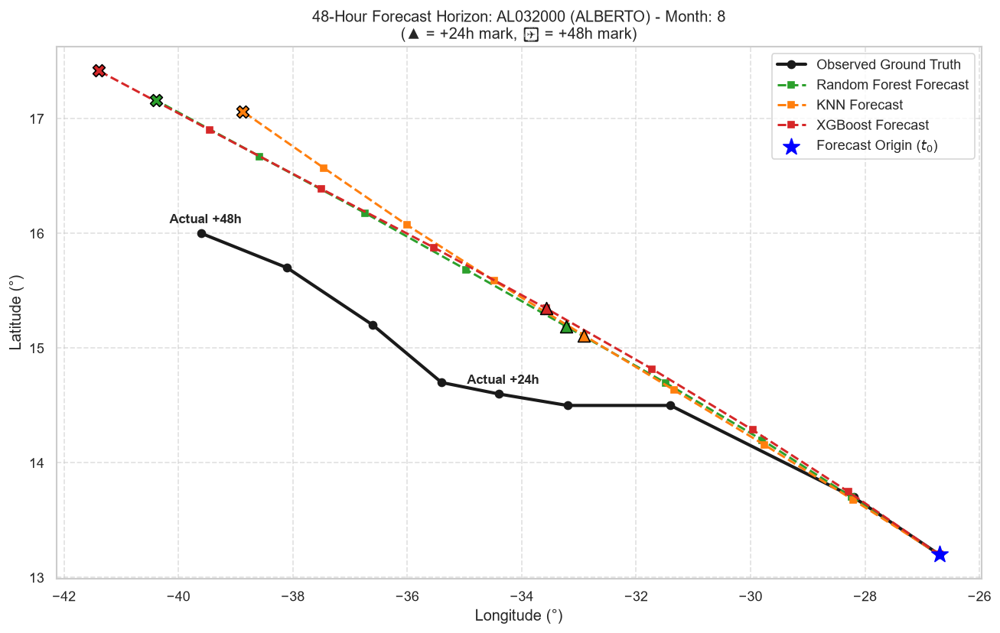


Computing Haversine displacement errors over horizons...


d:\Projects\hurricane\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Projects\hurricane\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Projects\hurricane\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Projects\hurricane\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `

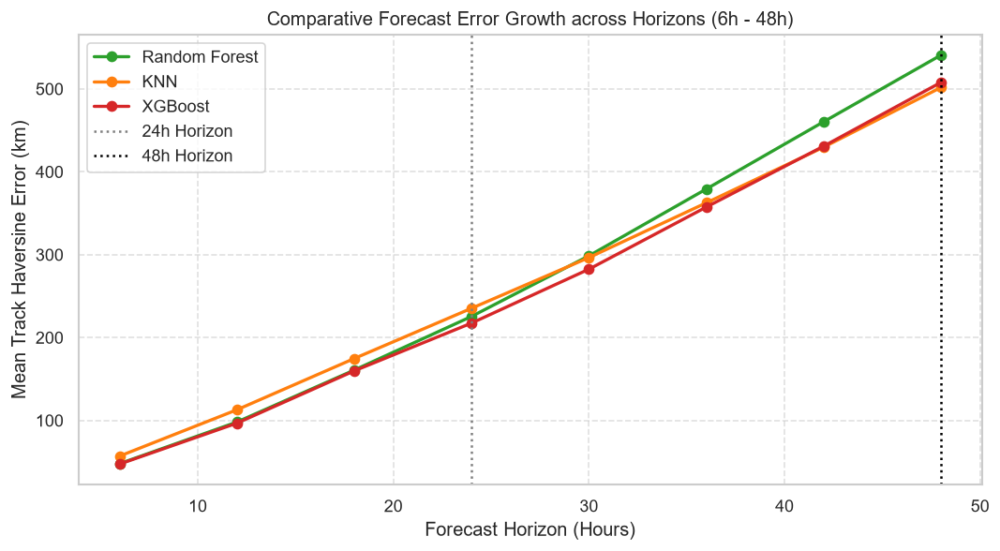

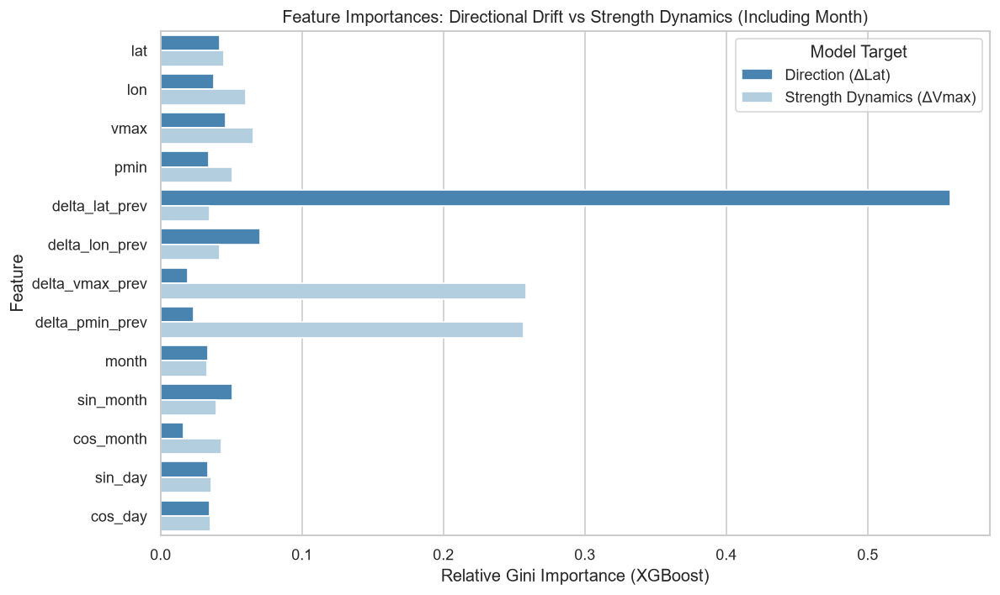

Computing SHAP values for seasonal and physical factor dependencies...


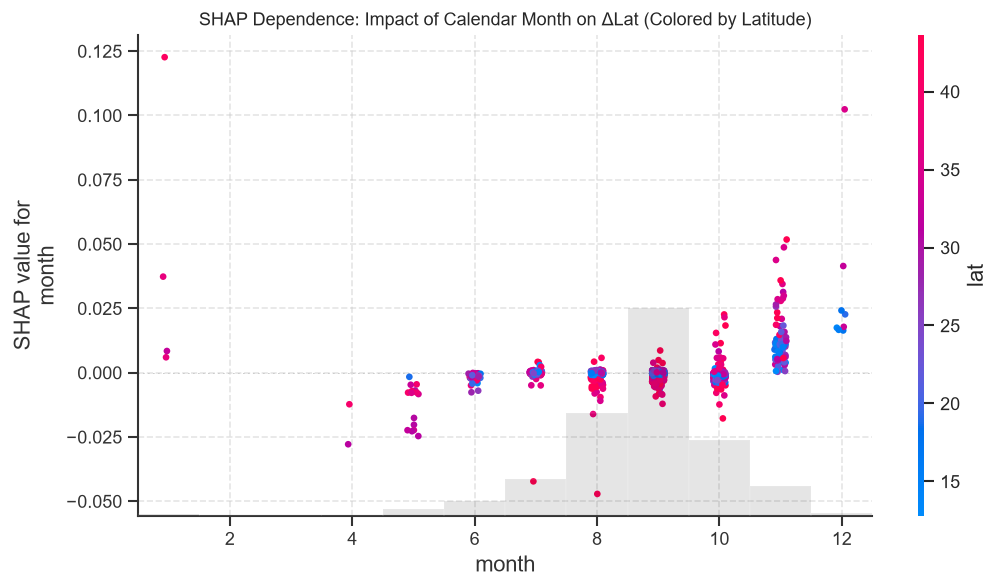

In [10]:
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from xgboost import XGBRegressor
import shap

# Visualization aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 10, "figure.autolayout": True})

HURDAT_URL = "https://www.nhc.noaa.gov/data/hurdat/hurdat2-1851-2023-051124.txt"
LOCAL_CSV = "hurdat2.csv"

# ==============================================================================
# 1. INGESTION, PARSING & QUALITY CONTROL FILTERING
# ==============================================================================

def download_dataset(filepath: str = LOCAL_CSV):
    """Downloads official Atlantic HURDAT2 dataset from NOAA NHC if missing."""
    if not os.path.exists(filepath):
        print(f"Downloading HURDAT2 archive to '{filepath}'...")
        urllib.request.urlretrieve(HURDAT_URL, filepath)
        print("Download complete.")
    else:
        print(f"Using local file: '{filepath}'")


def parse_and_clean_hurdat2(filepath: str, min_year: int = 1975) -> pd.DataFrame:
    """
    Parses HURDAT2, filters out historical records prior to min_year,
    and purges unrecorded sentinel flags (-999, 999, -99).
    """
    records = []
    current_id, current_name = None, None

    with open(filepath, "r") as f:
        for line in f:
            tokens = [t.strip() for t in line.split(",")]
            if len(tokens) >= 3 and tokens[0].startswith(("AL", "EP", "CP")):
                current_id = tokens[0]
                current_name = tokens[1]
            elif len(tokens) >= 8 and current_id is not None:
                date_str = tokens[0]      # YYYYMMDD
                time_str = tokens[1]      # HHMM
                status = tokens[3]
                lat_raw = tokens[4]
                lon_raw = tokens[5]
                
                try:
                    vmax = float(tokens[6])
                    pmin = float(tokens[7])
                except ValueError:
                    continue

                year = int(date_str[:4])
                # Filter out older storms prior to modern satellite surveillance era
                if year < min_year:
                    continue

                # Filter out -999, 999, -99 sentinel flags
                if pmin in [-999.0, 999.0, -99.0] or pmin < 850.0 or pmin > 1040.0:
                    continue
                if vmax in [-999.0, 999.0, -99.0] or vmax <= 0.0:
                    continue

                # Coordinates: North/East (+), South/West (-)
                lat = float(lat_raw[:-1]) * (-1.0 if lat_raw.endswith("S") else 1.0)
                lon = float(lon_raw[:-1]) * (-1.0 if lon_raw.endswith("W") else 1.0)

                records.append({
                    "storm_id": current_id,
                    "storm_name": current_name,
                    "timestamp": pd.to_datetime(f"{date_str} {time_str}", format="%Y%m%d %H%M"),
                    "lat": lat,
                    "lon": lon,
                    "vmax": vmax,
                    "pmin": pmin,
                    "status": status
                })

    df = pd.DataFrame(records)
    print(f"Post-filtering (Year >= {min_year}, valid Pmin/Vmax): {len(df):,} records across {df['storm_id'].nunique():,} cyclones.")
    return df


def engineer_cyclone_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Computes kinematics, intensity gradients, and calendar month encodings.
    """
    df = df.sort_values(by=["storm_id", "timestamp"]).reset_index(drop=True)

    # 1. Forward Targets (6-hour trajectory step deltas)
    df["delta_lat_next"] = df.groupby("storm_id")["lat"].shift(-1) - df["lat"]
    df["delta_lon_next"] = df.groupby("storm_id")["lon"].shift(-1) - df["lon"]
    df["delta_vmax_next"] = df.groupby("storm_id")["vmax"].shift(-1) - df["vmax"]

    # 2. Backward Kinematic Features (prior 6-hour steering flow velocities)
    df["delta_lat_prev"] = df["lat"] - df.groupby("storm_id")["lat"].shift(1)
    df["delta_lon_prev"] = df["lon"] - df.groupby("storm_id")["lon"].shift(1)
    df["delta_vmax_prev"] = df["vmax"] - df.groupby("storm_id")["vmax"].shift(1)
    df["delta_pmin_prev"] = df["pmin"] - df.groupby("storm_id")["pmin"].shift(1)

    # 3. Calendar Month & Seasonal Embeddings
    month = df["timestamp"].dt.month
    df["month"] = month
    df["sin_month"] = np.sin(2 * np.pi * month / 12.0)
    df["cos_month"] = np.cos(2 * np.pi * month / 12.0)

    # Day of year cyclical variation
    doy = df["timestamp"].dt.dayofyear
    df["sin_day"] = np.sin(2 * np.pi * doy / 365.25)
    df["cos_day"] = np.cos(2 * np.pi * doy / 365.25)

    # Drop boundary artifacts where leads or lags do not exist
    clean_df = df.dropna(subset=[
        "delta_lat_prev", "delta_lon_prev", "delta_vmax_prev", "delta_pmin_prev",
        "delta_lat_next", "delta_lon_next", "delta_vmax_next"
    ]).copy()

    # Filter out storms that don't have enough observations for a 48h (8 step) horizon
    storm_counts = clean_df["storm_id"].value_counts()
    valid_storms = storm_counts[storm_counts >= 9].index
    clean_df = clean_df[clean_df["storm_id"].isin(valid_storms)].reset_index(drop=True)

    return clean_df


# ==============================================================================
# 2. GEOGRAPHICAL SPHERICAL DISTANCE
# ==============================================================================

def haversine_vectorized(lat1, lon1, lat2, lon2) -> np.ndarray:
    """Great-circle distance in kilometers using the Haversine formula."""
    R = 6371.0  # Earth's mean radius in km
    p1, l1, p2, l2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dp = p2 - p1
    dl = l2 - l1
    a = np.sin(dp / 2.0)**2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2.0)**2
    c = 2 * np.arcsin(np.clip(np.sqrt(a), 0.0, 1.0))
    return R * c


# ==============================================================================
# 3. MULTI-MODEL BENCHMARK SUITE
# ==============================================================================

def train_cyclone_models(clean_df: pd.DataFrame):
    """
    Fits Random Forest, KNN, and XGBoost models on a Grouped split by storm ID.
    """
    feature_cols = [
        "lat", "lon", "vmax", "pmin",
        "delta_lat_prev", "delta_lon_prev",
        "delta_vmax_prev", "delta_pmin_prev",
        "month", "sin_month", "cos_month",
        "sin_day", "cos_day"
    ]

    splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
    train_idx, test_idx = next(splitter.split(clean_df, groups=clean_df["storm_id"]))

    train_df = clean_df.iloc[train_idx]
    test_df = clean_df.iloc[test_idx]

    X_train = train_df[feature_cols]
    X_test = test_df[feature_cols]

    models = {
        "Random Forest": {
            "dlat": RandomForestRegressor(n_estimators=120, max_depth=12, n_jobs=-1, random_state=42),
            "dlon": RandomForestRegressor(n_estimators=120, max_depth=12, n_jobs=-1, random_state=42),
            "dvmax": RandomForestRegressor(n_estimators=120, max_depth=12, n_jobs=-1, random_state=42)
        },
        "KNN": {
            "dlat": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=18, weights="distance")),
            "dlon": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=18, weights="distance")),
            "dvmax": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=18, weights="distance"))
        },
        "XGBoost": {
            "dlat": XGBRegressor(n_estimators=180, max_depth=6, learning_rate=0.04, subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1),
            "dlon": XGBRegressor(n_estimators=180, max_depth=6, learning_rate=0.04, subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1),
            "dvmax": XGBRegressor(n_estimators=180, max_depth=6, learning_rate=0.04, subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1)
        }
    }

    print("\nFitting models across target variables...")
    for name, m_dict in models.items():
        print(f"Training {name}...")
        m_dict["dlat"].fit(X_train, train_df["delta_lat_next"])
        m_dict["dlon"].fit(X_train, train_df["delta_lon_next"])
        m_dict["dvmax"].fit(X_train, train_df["delta_vmax_next"])

    return models, train_df, test_df, feature_cols


# ==============================================================================
# 4. AUTOREGRESSIVE FORECASTING (24h - 48h)
# ==============================================================================

def simulate_bounded_horizon(sub_models, initial_row: pd.Series, feature_cols: list, max_steps: int = 8) -> np.ndarray:
    """
    Simulates bounded autoregressive rollout for max_steps (8 steps = 48h).
    """
    state = initial_row.to_dict()
    forecast = [(state["lat"], state["lon"], state["vmax"])]

    for _ in range(max_steps):
        row_input = pd.DataFrame([{col: state[col] for col in feature_cols}])

        dlat = float(sub_models["dlat"].predict(row_input)[0])
        dlon = float(sub_models["dlon"].predict(row_input)[0])
        dvmax = float(sub_models["dvmax"].predict(row_input)[0])

        # Step update
        state["lat"] += dlat
        state["lon"] += dlon
        state["vmax"] = max(10.0, state["vmax"] + dvmax)
        state["delta_lat_prev"] = dlat
        state["delta_lon_prev"] = dlon
        state["delta_vmax_prev"] = dvmax

        forecast.append((state["lat"], state["lon"], state["vmax"]))

    return np.array(forecast)


# ==============================================================================
# 5. COMPARATIVE VISUALIZATIONS & FACTOR DEPENDENCIES
# ==============================================================================

def plot_horizon_comparison(test_df: pd.DataFrame, models: dict, feature_cols: list, storm_id: str, start_index: int = 2):
    """
    Plots the 48-hour trajectory projection from an initial point.
    Markers highlight +24h (▲) and +48h (✖) against ground truth.
    """
    storm_subset = test_df[test_df["storm_id"] == storm_id].sort_values("timestamp").reset_index(drop=True)
    if len(storm_subset) < (start_index + 9):
        print(f"Insufficient steps for {storm_id} starting at index {start_index}.")
        return

    init_row = storm_subset.iloc[start_index]
    actual_track = storm_subset.iloc[start_index:start_index + 9][["lat", "lon", "vmax"]].to_numpy()

    fig, ax = plt.subplots(figsize=(11, 7), dpi=120)
    ax.plot(actual_track[:, 1], actual_track[:, 0], "k-o", label="Observed Ground Truth", linewidth=2.5, markersize=6)

    colors = {"Random Forest": "#2ca02c", "KNN": "#ff7f0e", "XGBoost": "#d62728"}

    for name, sub_models in models.items():
        preds = simulate_bounded_horizon(sub_models, init_row, feature_cols, max_steps=8)
        ax.plot(preds[:, 1], preds[:, 0], "--s", color=colors[name], label=f"{name} Forecast", linewidth=1.8, markersize=5)
        # Highlight +24h and +48h marks
        ax.scatter(preds[4, 1], preds[4, 0], color=colors[name], s=90, marker="^", edgecolors="black", zorder=5)
        ax.scatter(preds[8, 1], preds[8, 0], color=colors[name], s=90, marker="X", edgecolors="black", zorder=5)

    # Initial state
    ax.scatter(actual_track[0, 1], actual_track[0, 0], color="blue", s=180, marker="*", zorder=6, label="Forecast Origin ($t_0$)")
    ax.annotate("Actual +24h", (actual_track[4, 1], actual_track[4, 0]), textcoords="offset points", xytext=(-25, 8), fontweight="bold")
    ax.annotate("Actual +48h", (actual_track[8, 1], actual_track[8, 0]), textcoords="offset points", xytext=(-25, 8), fontweight="bold")

    ax.set_xlabel("Longitude (°)")
    ax.set_ylabel("Latitude (°)")
    ax.set_title(f"48-Hour Forecast Horizon: {storm_id} ({init_row['storm_name']}) - Month: {int(init_row['month'])}\n(▲ = +24h mark, ✖ = +48h mark)", fontsize=12)
    ax.legend(loc="best")
    ax.grid(True, linestyle="--", alpha=0.6)
    plt.tight_layout()
    plt.show()


def plot_error_growth_curve(test_df: pd.DataFrame, models: dict, feature_cols: list, num_samples: int = 50):
    """
    Evaluates Great-Circle displacement error (km) across all models from 6h to 48h.
    """
    print("\nComputing Haversine displacement errors over horizons...")
    eligible_storms = [sid for sid, grp in test_df.groupby("storm_id") if len(grp) >= 12]
    np.random.seed(42)
    sample_storms = np.random.choice(eligible_storms, size=min(num_samples, len(eligible_storms)), replace=False)

    horizons = np.arange(1, 9) * 6  # 6h, 12h, ..., 48h
    errors = {name: {h: [] for h in horizons} for name in models.keys()}

    for sid in sample_storms:
        group = test_df[test_df["storm_id"] == sid].sort_values("timestamp").reset_index(drop=True)
        max_start = len(group) - 9
        if max_start <= 0:
            continue
        start_idx = np.random.randint(0, max_start)
        init_row = group.iloc[start_idx]
        actual_coords = group.iloc[start_idx + 1:start_idx + 9][["lat", "lon"]].to_numpy()

        for name, sub_models in models.items():
            preds = simulate_bounded_horizon(sub_models, init_row, feature_cols, max_steps=8)[1:, :2]
            dists = haversine_vectorized(actual_coords[:, 0], actual_coords[:, 1], preds[:, 0], preds[:, 1])
            for step_i, h in enumerate(horizons):
                errors[name][h].append(dists[step_i])

    plt.figure(figsize=(9, 5), dpi=120)
    palette = {"Random Forest": "#2ca02c", "KNN": "#ff7f0e", "XGBoost": "#d62728"}
    for name, h_data in errors.items():
        mean_errs = [np.mean(h_data[h]) for h in horizons]
        plt.plot(horizons, mean_errs, "-o", label=name, color=palette[name], linewidth=2)

    plt.axvline(24, color="gray", linestyle=":", label="24h Horizon")
    plt.axvline(48, color="black", linestyle=":", label="48h Horizon")
    plt.xlabel("Forecast Horizon (Hours)")
    plt.ylabel("Mean Track Haversine Error (km)")
    plt.title("Comparative Forecast Error Growth across Horizons (6h - 48h)", fontsize=12)
    plt.legend(loc="upper left")
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.tight_layout()
    plt.show()


def plot_factor_dependencies(models, X_train: pd.DataFrame, feature_cols: list):
    """
    Renders feature importance comparisons and SHAP non-linear dependency plots,
    highlighting the role of seasonal month and core physical variables.
    """
    xgb_dlat = models["XGBoost"]["dlat"]
    xgb_dvmax = models["XGBoost"]["dvmax"]

    importance_df = pd.DataFrame({
        "Feature": feature_cols,
        "Direction (ΔLat)": xgb_dlat.feature_importances_,
        "Strength Dynamics (ΔVmax)": xgb_dvmax.feature_importances_
    }).melt(id_vars="Feature", var_name="Model Target", value_name="Importance")

    fig, ax = plt.subplots(figsize=(10, 6), dpi=120)
    sns.barplot(data=importance_df, x="Importance", y="Feature", hue="Model Target", palette="Blues_r", ax=ax)
    ax.set_title("Feature Importances: Directional Drift vs Strength Dynamics (Including Month)", fontsize=12)
    ax.set_xlabel("Relative Gini Importance (XGBoost)")
    plt.tight_layout()
    plt.show()

    # SHAP Partial Dependence: Effect of Month and Latitude on Trajectory Direction
    print("Computing SHAP values for seasonal and physical factor dependencies...")
    sample_shap = X_train.sample(n=min(1200, len(X_train)), random_state=42)
    explainer = shap.TreeExplainer(xgb_dlat)
    shap_vals = explainer(sample_shap)

    fig, ax = plt.subplots(figsize=(9, 5), dpi=120)
    shap.plots.scatter(shap_vals[:, "month"], color=shap_vals[:, "lat"], ax=ax, show=False)
    ax.set_title("SHAP Dependence: Impact of Calendar Month on ΔLat (Colored by Latitude)", fontsize=11)
    ax.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


# ==============================================================================
# 6. PIPELINE EXECUTION
# ==============================================================================

if __name__ == "__main__":
    download_dataset(LOCAL_CSV)
    
    # 1. Parse and filter out older storms (<1975) and sentinel values (-999, 999)
    raw_df = parse_and_clean_hurdat2(LOCAL_CSV, min_year=1975)
    
    # 2. Build feature matrix with month encodings
    clean_df = engineer_cyclone_features(raw_df)

    # 3. Train benchmark suite: RF, KNN, XGBoost
    models, train_df, test_df, features = train_cyclone_models(clean_df)

    # 4. Trajectory forecast comparison on a holdout storm
    test_storms = test_df["storm_id"].value_counts()
    target_storm = test_storms.index[0]
    print(f"\nSimulating 48h horizon for holdout test storm: {target_storm}")
    plot_horizon_comparison(test_df, models, features, storm_id=target_storm, start_index=4)

    # 5. Forecast error curve from 6h to 48h
    plot_error_growth_curve(test_df, models, features, num_samples=40)

    # 6. Factor dependencies: Direction & Strength vs Month, Pressure, Velocity
    plot_factor_dependencies(models, train_df[features], features)